In [ ]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import skfda
import sys

from scipy.integrate import simpson
from skfda.preprocessing.dim_reduction import FPCA
from skfda.representation.basis import BSplineBasis

sys.path.append("[insert root path]/fcpt/functions")
import fNIRSData
import funcChangePoint
import auxFuncChPt

import importlib
importlib.reload(fNIRSData)
importlib.reload(funcChangePoint)
importlib.reload(auxFuncChPt)

Nothing done.


<module 'COPYauxFuncChPt' from '/Users/sambe/Documents/Python_Projects/FDA/functions/COPYauxFuncChPt.py'>

Define input file/output filename (if you want to save) and the channels you wish to analyse (i,e. ROI channels)
<br> If adding more channels, the blocks of code which need to be included in a for loop are indicated below in the notebook.

In [ ]:
dataFile = '[insert root path]/fcpt/dataRaw/homer2GM12moDataFrame.pkl'
outputFilename = '[insert root path]/fcpt/data/homer2GM12moHbOChPtFF.pkl'
numChan = 3 #run on channels =  [3, 4, 8, 9, 12, 18, 19] for all ROI channels
firstTrial = 1
lastTrial = 25

In [87]:
firstFunc = firstTrial-1
lastFunc = lastTrial-1
lastTrialTotal = lastTrial
numChrom = 1
numBasis = 12
firstSamp = -20
lastSamp = 182
gridPoints = np.arange(firstSamp, lastSamp, 1)

In [88]:
columnList = ['Channel',
'Chromophore',
'First Trial',
'Last Trial',
'Change Point',
'Max. T_N',
'p-value']

dfChangePoint = pd.DataFrame(columns = columnList)

If working with multiple channels, group the following 4 blocks of code together and run inside a for loop, i.e.:
<br> for numChan in channels: 


In [89]:

dataMatrix = fNIRSData.groupDataMatrix(dataFile,
                                    numChan,
                                    numChrom,
                                    firstTrial,
                                    lastTrial)


In [90]:

fd = skfda.FDataGrid(
    data_matrix=dataMatrix,
    grid_points=gridPoints,
)

basis = BSplineBasis(n_basis=numBasis)
fdObj = fd.to_basis(basis)

In [91]:
fdObj.coefficients.shape

(25, 12)

In [93]:
chanMat = (auxFuncChPt.findCPtsFF(fdObj, firstFunc, lastFunc)).astype('float32')
chanMat = np.delete(chanMat, (0), axis=0) #deletes a dummy row in the matrix which is added during it's creation

In [106]:
chanMat

array([[1.0000000e+00, 2.5000000e+01, 1.3000000e+01, 2.9786967e-13,
        8.9999998e-04],
       [1.0000000e+00, 1.2000000e+01, 5.0000000e+00, 6.8253244e-14,
        1.1300000e-02],
       [1.0000000e+00, 4.0000000e+00, 2.0000000e+00, 1.7492916e-14,
        1.1300000e-01],
       [5.0000000e+00, 1.2000000e+01, 8.0000000e+00, 2.1752072e-14,
        2.6580000e-01],
       [1.3000000e+01, 2.5000000e+01, 1.8000000e+01, 5.3553865e-14,
        2.6530001e-01]], dtype=float32)

In [94]:

for i in range(chanMat.shape[0]):
    dfChangePoint = pd.concat([dfChangePoint, pd.DataFrame.from_records([{
        'Channel':numChan,
        'Chromophore':numChrom,
        'First Trial':(chanMat[i][0]+1),
        'Last Trial': (chanMat[i][1]+1),
        'Change Point': (chanMat[i][2]+1),
        'Max. T_N': (chanMat[i][3]),
        'p-value': (chanMat[i][4])
        }])])

In [95]:
dfChangePoint

,Channel,Chromophore,First Trial,Last Trial,Change Point,Max. T_N,p-value
0,3,1,1.0,25.0,13.0,2.978697e-13,0.0009
0,3,1,1.0,12.0,5.0,6.825324e-14,0.0113
0,3,1,1.0,4.0,2.0,1.749292e-14,0.1130
0,3,1,5.0,12.0,8.0,2.175207e-14,0.2658
0,3,1,13.0,25.0,18.0,5.355386e-14,0.2653


In [96]:
#save the participant's nested dictionary
#with open(outputFilename, 'wb') as f:
#    pickle.dump(dfChangePoint, f)

In [97]:
df = dfChangePoint[dfChangePoint['p-value'] <= 0.05]
df

,Channel,Chromophore,First Trial,Last Trial,Change Point,Max. T_N,p-value
0,3,1,1.0,25.0,13.0,2.978697e-13,0.0009
0,3,1,1.0,12.0,5.0,6.825324e-14,0.0113


Again, if using more than one channel, group following 5 blocks inside a for loop i.e.:
<br>for numChan in channels:

In [99]:
dfChan = (df[df['Channel'] == numChan]).sort_values(by=['Change Point'])

changeColumn = (dfChan.get('Change Point').tolist())
changeColumn = [int(x) for x in changeColumn]
changeColumn.append(lastTrialTotal + 1)

In [101]:
iBlock = 0
tempTrial = 1

blockMeans = np.empty([len(changeColumn), (abs(firstSamp)+abs(lastSamp))])
for point in changeColumn:
    firstTrial = tempTrial
    lastTrial = point-1 #-1 because dataMatrix rows go from 0->(numTrials-1)
    blockMatrix = dataMatrix[firstTrial-1:lastTrial-1, ]
    blockMeans[iBlock] = np.mean(blockMatrix, axis = 0)
    tempTrial = point
    iBlock = iBlock + 1


In [102]:
changeColumn.insert(0,1)
volChans = []

volNoHab = simpson(blockMeans[0, 21:], dx = 1) * lastTrialTotal
volHab = 0
for i in range(0, len(changeColumn)-1):
    volTrial = (simpson(blockMeans[i, 21:], dx = 1)) * (changeColumn[i+1] - changeColumn[i])
    volHab = volHab + volTrial


In [103]:

ratioHab = (volHab / volNoHab)
volChans.append(ratioHab)
print(ratioHab)
    

0.6962003850016104


<Axes: >

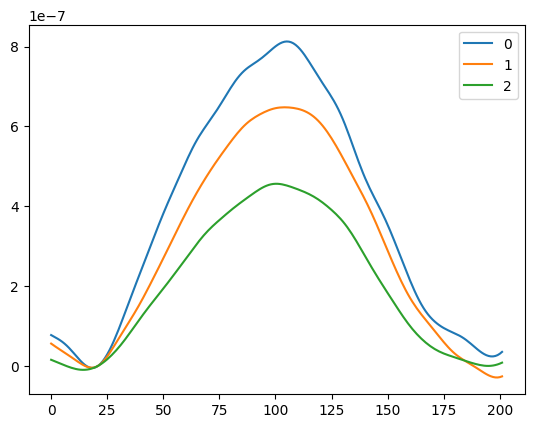

In [104]:
#plotting here works well on 12mo GM channel 3
trialFrame = pd.DataFrame(data=blockMeans)
trialFrame = trialFrame.T

trialFrame.plot()